# Method 5: State-space (Kalman) shrinkage
Keep a running best guess of each stat's true rate and update it after every match.

**Model, per stat.** The true rate `theta` starts at the group mean `mu` with spread `tau2` (how much players differ). After each match it can drift by a random amount with variance `delta2`. A match with `m` minutes is observed as `y ~ Normal(theta, sigma2 / m)`. All four parameters are fit by maximum likelihood on the training players' match sequences.

**Update.** After each match the guess moves by `gain x (y - guess)`, with `gain = P / (P + sigma2/m)` and `P` the current uncertainty: early matches and long matches pull hard, a confident guess and a short cameo pull little. With `delta2 = 0` this is exactly minutes shrinkage (`k = sigma2 / tau2`), so the fitted `delta2` measures within-season drift in form.

Three methods use it:

| Method | Estimate |
|---|---|
| `kalman` | the filtered rate after the matches seen so far |
| `kalman_blend` | the full-season per-90 contains the minutes already seen, so `m/Mbar x observed + (1 - m/Mbar) x filtered rate`, with `Mbar` the mean training full-season minutes (a modelling choice) |
| `ridge_kalman` | the final ridge plus the filtered rate (and its product with `s(m)`) as extra features |

**Setup shared by every method.** One model per gender and position group, trained on every per-game prefix (the player's first k matches, up to 750 minutes) of the 900+ minute player-seasons, each with its full-season per-90 as the target. The same fitted model handles any number of minutes. Rates, ratios and percents are never estimated: they are rebuilt from the estimated per-90 volumes.

In [1]:
%matplotlib inline
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
# make the repo root importable no matter which folder the notebook is opened from
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "low_minute_player_analysis").is_dir())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from low_minute_player_analysis import notebook_helpers as nh
from low_minute_player_analysis import reconstruct_methods as rm
from low_minute_player_analysis import temporal_methods as tm
from low_minute_player_analysis import reconstruction_eval as ev

nh.apply_style()
r = nh.load_results("results")         # out-of-fold scores for every group, gender and method
V, R = nh.volume(r), nh.rates(r)       # volume stats / rates rebuilt from the estimated volumes
P = nh.load_paired("results")          # paired differences vs the final ridge, with bootstrap intervals
nh.describe(r)

79,101 scored rows | genders ['female', 'male'] | 7 groups | checkpoints [np.int64(250), np.int64(500), np.int64(750)] | methods ['raw', 'shrink', 'ridge', 'knn', 'ot_1d', 'ot_joint', 'ot_group', 'kalman', 'kalman_blend', 'ridge_kalman', 'gru']
volume stats scored: 113 | rebuilt rates scored: 74


## 1. Results across all 14 gender / position-group sets

**How to read the numbers.** `nrmse` is the RMSE of the estimate against the player's true full-season
per-90, divided by the standard deviation of that true value. 0 is perfect; 1 means no better than guessing
the group average. Every table shows the **median over stats** (and over groups/genders unless stated).
The three columns / x positions are **minutes bins** of the sample the estimate was made from: 250 = 0-375 minutes,
500 = 375-625, 750 = 625-750 (every per-game prefix of a held-out player is scored; each player-season counts once
per bin). Scores are out-of-fold: the 5 folds split players, so nobody is predicted by a model that saw them.

method,raw,shrink,kalman,kalman_blend,ridge,ridge_kalman
checkpoint,,,,,,
250,1.489,0.817,0.813,0.799,0.769,0.764
500,0.713,0.618,0.608,0.580,0.552,0.552
750,0.518,0.524,0.507,0.464,0.457,0.455


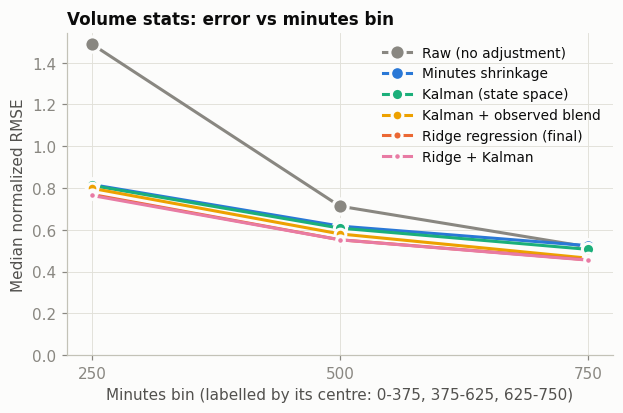

In [2]:
METHODS = ["raw", "shrink", "kalman", "kalman_blend", "ridge", "ridge_kalman"]
summary = nh.median_nrmse(V, METHODS)
display(summary.round(3))
nh.curve_plot(summary, METHODS, "Volume stats: error vs minutes bin")
plt.show()

Paired difference in squared error versus the final ridge, per player-season (negative = better than ridge). `better` / `worse` count the gender-group sets (of 14) where the 95% bootstrap interval is entirely below / above 0.

In [3]:
display(nh.paired_summary(P, ["shrink", "kalman", "kalman_blend", "ridge_kalman"]).round(4))

mean_diff  better  worse  sets
method       checkpoint                                
shrink       250            0.0882       0     12    14
             500            0.1258       0     14    14
             750            0.1153       0     13    14
kalman       250            0.1496       0     11    14
             500            0.3137       0     14    14
             750            0.1037       0     13    14
kalman_blend 250            0.0832       0     11    14
             500            0.1128       0     13    14
             750           -0.0194       3      7    14
ridge_kalman 250           -0.0252      13      0    14
             500           -0.0011       8      1    14
             750           -0.0147       9      0    14

### Rates rebuilt from the estimated volumes

In [4]:
display(nh.median_nrmse(R, METHODS).round(3).rename_axis("minutes bin"))
display(nh.missing_table(R, METHODS).round(4))

method,raw,shrink,kalman,kalman_blend,ridge,ridge_kalman
minutes bin,,,,,,
250,1.737,0.911,0.903,0.901,0.857,0.843
500,0.838,0.721,0.718,0.707,0.654,0.650
750,0.610,0.606,0.612,0.569,0.564,0.560


,n_truth_ok,n_est_missing,n_compared,est_missing_share
method,,,,
raw,17532604,1039980,16492624,0.0593
shrink,17532604,139671,17392933,0.0080
kalman,17532604,140005,17392599,0.0080
kalman_blend,17532604,152685,17379919,0.0087
ridge,17532604,162703,17369901,0.0093
ridge_kalman,17532604,162126,17370478,0.0092


## 2. Worked example: male Wingers (live run)
Parameters fitted on all of this group's prefixes (descriptive). `drift_ratio = delta2 / tau2` is the share of the between-player variance that is added per match by drift in form; `k_minutes = sigma2 / tau2` is the shrinkage constant.

In [5]:
stems, _ = ev.group_setup("male", "Wingers")
pool = ev.load_pool("male", "Wingers", stems)
params = tm.fit_kalman(pool, stems)
par = pd.DataFrame(params.T, index=stems, columns=["mu", "tau2", "delta2", "sigma2"])
par["drift_ratio"] = par.delta2 / par.tau2
par["k_minutes"] = par.sigma2 / par.tau2
solid = par[par.tau2 > 1e-4]          # skip stats so rare that tau2 is ~0 and the ratios are meaningless
print(f"{len(solid)} of {len(par)} stats have a well-defined between-player variance")
display(solid[["drift_ratio", "k_minutes"]].describe().round(3))
display(solid.loc[["passes", "shots", "key_passes", "interceptions", "touches_in_box"] if "touches_in_box" in solid.index else solid.index[:5],
                  ["mu", "tau2", "delta2", "sigma2", "drift_ratio", "k_minutes"]].round(4))

94 of 100 stats have a well-defined between-player variance


,drift_ratio,k_minutes
count,94.000,94.000
mean,0.029,1655.167
std,0.064,5456.051
min,0.000,90.145
25%,0.000,216.313
50%,0.020,344.347
75%,0.040,879.893
max,0.606,46502.340


,mu,tau2,delta2,sigma2,drift_ratio,k_minutes
goals,0.2282,0.0071,0.0000,21.2004,0.0000,2968.7061
assists,0.1389,0.0003,0.0000,13.5381,0.0001,46502.3398
shots,1.7855,0.4133,0.0068,177.2422,0.0165,428.8611
head_shots,0.1344,0.0134,0.0015,12.0382,0.1107,896.6143
yellow_cards,0.1249,0.0014,0.0000,10.5184,0.0000,7317.2212


### Diagnostic: filtered rate for a few player-seasons
Dots are single matches (per 90), the line is the running per-90, the orange line is the Kalman estimate, the dashed line is the full-season truth.

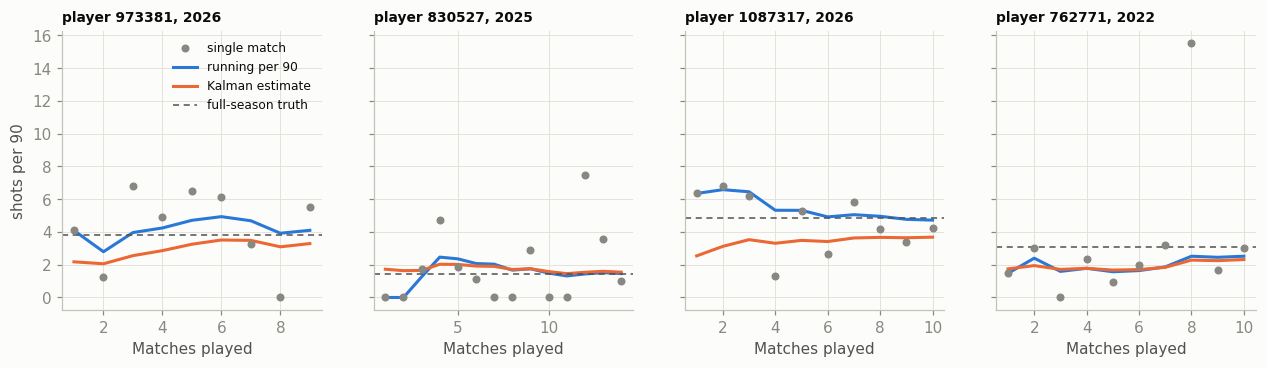

In [6]:
s = "shots"; i = stems.index(s)
seasons = pool.groupby(["player_id", "year"]).size()
pick = seasons[seasons >= 9].sample(4, random_state=1).index
fig, axes = plt.subplots(1, 4, figsize=(14, 3.3), sharey=True)
for ax, (pid, yr) in zip(axes, pick):
    d = pool[(pool.player_id == pid) & (pool.year == yr)]
    sq = tm.build_seq(d, stems)
    theta = tm.kalman_theta(d, stems, params)[:, i]
    ax.scatter(d["n_matches"], sq["match_p90"][0, :len(d), i], s=18, color=nh.COLORS["raw"], zorder=3, label="single match")
    ax.plot(d["n_matches"], d[f"low_{s}"], color=nh.COLORS["shrink"], lw=2, label="running per 90")
    ax.plot(d["n_matches"], theta, color=nh.COLORS["ridge"], lw=2, label="Kalman estimate")
    ax.axhline(d[f"full_{s}"].iloc[0], color=nh.INK2, lw=1, ls=(0, (4, 3)), label="full-season truth")
    ax.set_xlabel("Matches played"); ax.set_title(f"player {pid}, {yr}", loc="left", fontsize=9)
axes[0].set_ylabel(f"{s} per 90"); axes[0].legend(fontsize=8)
plt.show()

### Strengths and limits
- Interpretable: `delta2` and `k_minutes` say how much form drifts and how noisy each stat is.
- Each stat is modelled separately, so it cannot use that stats move together; `ridge_kalman` adds that back.
- Assumes Normal noise, which fits counts of rare events (goals, penalties) poorly: for those stats `tau2` is near 0 and the ratios are not meaningful.
- `kalman_blend` depends on the mean full-season minutes `Mbar`, a modelling assumption.